## Fashion-MNIST ile Görüntü Sınıflandırma (CNN)

In [2]:
# Importlar
import time, json, random, platform
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "GPU yok (CPU)"
print("Cihaz       :", device)

Cihaz       : cuda


In [3]:
# Hiperparametreler
BATCH_SIZE    = 128
LEARNING_RATE = 1e-3
EPOCHS        = 15
VAL_SIZE      = 6000     # 60.000 eğitim görüntüsünden doğrulama için ayrılan kısım

### 1. Veri Hazırlığı

In [4]:
# Veriseti 54000 Eğitim, 6000 Doğrulama, 10000 Test şeklinde bölünecektir

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Fashion-MNIST eğitim kümesinin bilinen piksel ortalaması ve standart sapması
MEAN, STD = 0.2860, 0.3530

transform = transforms.Compose([
    transforms.ToTensor(),                    # [0,255] -> [0,1], şekil (1, 28, 28)
    transforms.Normalize((MEAN,), (STD,)),
])

full_train = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_set   = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

train_set, val_set = random_split(
    full_train,
    [len(full_train) - VAL_SIZE, VAL_SIZE],
    generator=torch.Generator().manual_seed(SEED),
)

print(f"Eğitim: {len(train_set)} | Doğrulama: {len(val_set)} | Test: {len(test_set)}")

# Sınıf dağılımı dengeli mi?
train_labels = full_train.targets[train_set.indices]
print("Eğitim kümesinde sınıf başına örnek sayısı:", torch.bincount(train_labels).tolist())

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.74MB/s]

Eğitim: 54000 | Doğrulama: 6000 | Test: 10000
Eğitim kümesinde sınıf başına örnek sayısı: [5342, 5389, 5388, 5438, 5393, 5387, 5400, 5463, 5402, 5398]


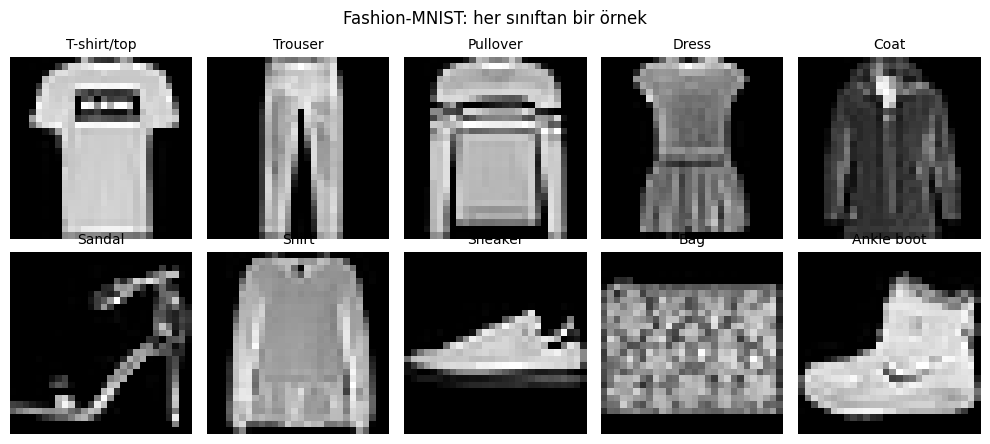

In [5]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# Her sınıftan bir örnek göster
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for c, ax in enumerate(axes.ravel()):
    idx = (full_train.targets == c).nonzero(as_tuple=True)[0][0]
    ax.imshow(full_train.data[idx], cmap="gray")
    ax.set_title(CLASS_NAMES[c], fontsize=10)
    ax.axis("off")
plt.suptitle("Fashion-MNIST: her sınıftan bir örnek")
plt.tight_layout()
plt.show()

### 2. Model ve Eğitim Ayarları

**Mimari (giriş 1×28×28):**

| Katman | Çıktı şekli |
|---|---|
| Conv(1→32, 3×3) + BatchNorm + ReLU + MaxPool | 32×14×14 |
| Conv(32→64, 3×3) + BatchNorm + ReLU + MaxPool | 64×7×7 |
| Conv(64→128, 3×3) + BatchNorm + ReLU + MaxPool | 128×3×3 |
| Flatten → Dropout → Linear(1152→128) + ReLU → Dropout → Linear(128→10) | 10 (logit) |

**Seçimlerin Kısaca Gerekçeleri:**
- **ReLU:** Basit, hızlı, kaybolan gradyan sorununu azaltır.
- **BatchNorm:** Eğitimi hızlandırır ve kararlı hâle getirir.
- **Dropout (0.3):** Aşırı öğrenmeyi azaltır.
- **Çıkış fonksiyonu:** Ağ ham skor üretir; olasılıklar için tahmin sırasında **Softmax** uygulanır.
- **CrossEntropyLoss:** Çok sınıflı sınıflandırma için uygundur.
- **Optimizer: Adam:** Öğrenme oranını parametre bazında uyarlar, az ayarla iyi sonuç verir.


In [6]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),  nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),  # 28 -> 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),  # 14 -> 7
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2), # 7 -> 3
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 3 * 3, 128), nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),   # logit çıktısı (Softmax yok; CrossEntropyLoss içinde)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = SimpleCNN().to(device)
num_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nToplam parametre sayısı: {num_params:,}")

# Şekil kontrolü: (1, 1, 28, 28) -> (1, 10) olmalı
print("Çıktı şekli:", tuple(model(torch.randn(1, 1, 28, 28, device=device)).shape))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_fea

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [8]:
# Eğitim Döngüsü

def run_epoch(loader, train=False):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

In [9]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc, best_epoch = 0.0, 0

if device.type == "cuda":
    torch.cuda.synchronize()
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)

    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)

    is_best = va_acc > best_val_acc
    if is_best:
        best_val_acc, best_epoch = va_acc, epoch
        torch.save(model.state_dict(), "fashion_cnn_best.pth")

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f}" + ("  <- en iyi" if is_best else ""))

if device.type == "cuda":
    torch.cuda.synchronize()
training_time = time.time() - t0

print(f"\nToplam eğitim süresi: {training_time:.1f} sn ({training_time/60:.1f} dk)")
print(f"En iyi doğrulama doğruluğu: {best_val_acc:.4f} (epoch {best_epoch})")

Epoch 01/15 | train loss 0.4713 acc 0.8292 | val loss 0.2976 acc 0.8918  <- en iyi
Epoch 02/15 | train loss 0.3071 acc 0.8888 | val loss 0.2670 acc 0.9000  <- en iyi
Epoch 03/15 | train loss 0.2639 acc 0.9042 | val loss 0.2520 acc 0.9072  <- en iyi
Epoch 04/15 | train loss 0.2387 acc 0.9126 | val loss 0.2369 acc 0.9107  <- en iyi
Epoch 05/15 | train loss 0.2194 acc 0.9193 | val loss 0.2191 acc 0.9178  <- en iyi
Epoch 06/15 | train loss 0.2003 acc 0.9262 | val loss 0.2250 acc 0.9182  <- en iyi
Epoch 07/15 | train loss 0.1886 acc 0.9306 | val loss 0.2023 acc 0.9260  <- en iyi
Epoch 08/15 | train loss 0.1784 acc 0.9341 | val loss 0.1993 acc 0.9262  <- en iyi
Epoch 09/15 | train loss 0.1666 acc 0.9399 | val loss 0.1921 acc 0.9312  <- en iyi
Epoch 10/15 | train loss 0.1566 acc 0.9428 | val loss 0.2057 acc 0.9255
Epoch 11/15 | train loss 0.1458 acc 0.9458 | val loss 0.1966 acc 0.9287
Epoch 12/15 | train loss 0.1416 acc 0.9480 | val loss 0.1929 acc 0.9312
Epoch 13/15 | train loss 0.1351 acc 0

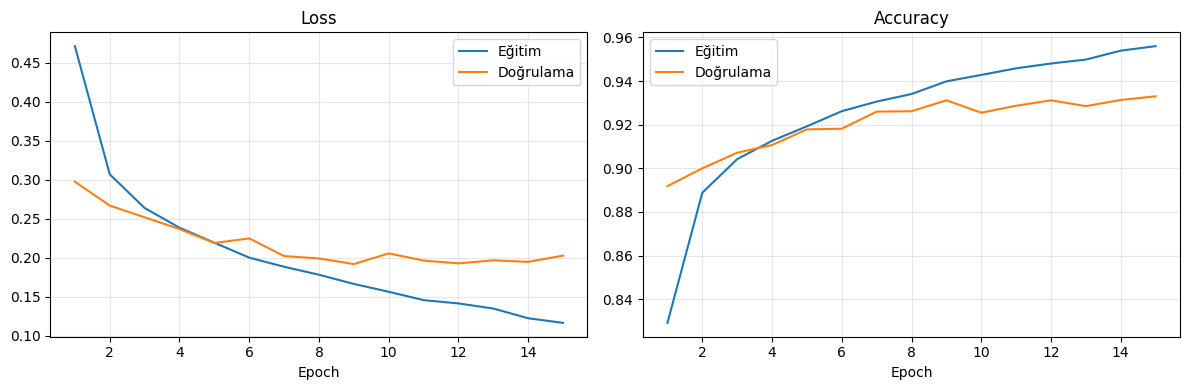

In [10]:
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], label="Eğitim")
axes[0].plot(epochs_range, history["val_loss"],   label="Doğrulama")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["train_acc"], label="Eğitim")
axes[1].plot(epochs_range, history["val_acc"],   label="Doğrulama")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3. Test Kümesinde Değerlendirme

In [11]:
model.load_state_dict(torch.load("fashion_cnn_best.pth", map_location=device))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds = model(x.to(device)).argmax(1).cpu()
        all_preds.append(preds)
        all_labels.append(y)

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

test_acc = float((y_pred == y_true).mean())
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")

print(f"Test Accuracy : {test_acc:.4f}")
print(f"Macro Precision: {prec:.4f} | Macro Recall: {rec:.4f} | Macro F1: {f1:.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

Test Accuracy : 0.9271
Macro Precision: 0.9271 | Macro Recall: 0.9271 | Macro F1: 0.9264

              precision    recall  f1-score   support

 T-shirt/top     0.8495    0.9260    0.8861      1000
     Trouser     0.9940    0.9890    0.9915      1000
    Pullover     0.8923    0.8950    0.8937      1000
       Dress     0.9281    0.9290    0.9285      1000
        Coat     0.8648    0.9080    0.8859      1000
      Sandal     0.9840    0.9840    0.9840      1000
       Shirt     0.8430    0.7250    0.7796      1000
     Sneaker     0.9792    0.9430    0.9608      1000
         Bag     0.9900    0.9880    0.9890      1000
  Ankle boot     0.9462    0.9840    0.9647      1000

    accuracy                         0.9271     10000
   macro avg     0.9271    0.9271    0.9264     10000
weighted avg     0.9271    0.9271    0.9264     10000



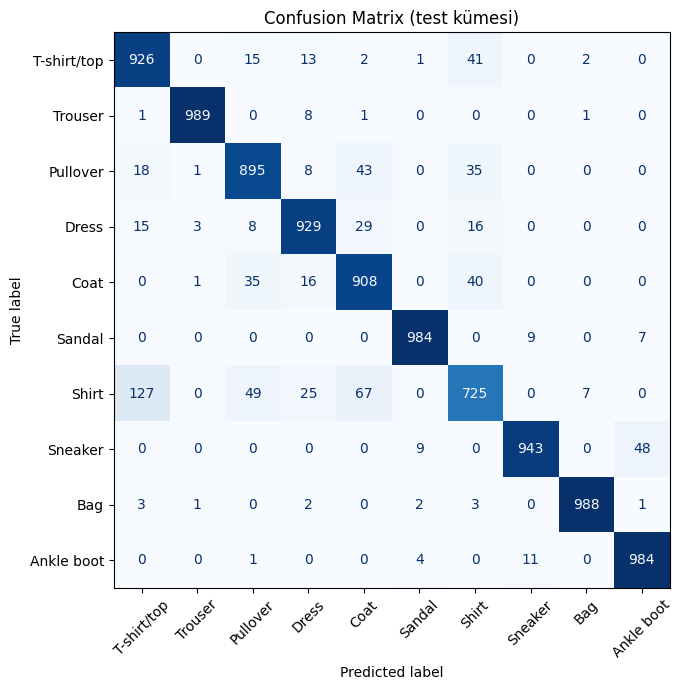

En sık karışan çiftler (gerçek -> tahmin):
  Shirt -> T-shirt/top: 127 görüntü
  Shirt -> Coat: 67 görüntü
  Shirt -> Pullover: 49 görüntü
  Sneaker -> Ankle boot: 48 görüntü
  Pullover -> Coat: 43 görüntü


In [12]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=CLASS_NAMES,
    xticks_rotation=45, cmap="Blues", ax=ax, colorbar=False,
)
ax.set_title("Confusion Matrix (test kümesi)")
plt.tight_layout()
plt.show()

# En sık karıştırılan 5 sınıf çifti
cm = confusion_matrix(y_true, y_pred)
off = cm.copy()
np.fill_diagonal(off, 0)
print("En sık karışan çiftler (gerçek -> tahmin):")
for flat in np.argsort(off, axis=None)[::-1][:5]:
    i, j = divmod(int(flat), len(CLASS_NAMES))
    print(f"  {CLASS_NAMES[i]} -> {CLASS_NAMES[j]}: {off[i, j]} görüntü")

In [13]:
# Tahmin süresi hesaplama
# Tek bir görüntü için ortalama tahmin süresi, ısınma turlarından sonra yüzlerce çalıştırmanın ortalaması olarak ölçülür.
# Gradio uygulaması gerçekte tek görüntü ile çalışacağı için batch = 1 ölçülüyor

def measure_inference_ms(dev, n_runs=300, n_warmup=30):
    m = SimpleCNN().to(dev)
    m.load_state_dict(torch.load("fashion_cnn_best.pth", map_location=dev))
    m.eval()
    x = torch.randn(1, 1, 28, 28, device=dev)
    with torch.no_grad():
        for _ in range(n_warmup):
            m(x)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        t = time.perf_counter()
        for _ in range(n_runs):
            m(x)
        if dev.type == "cuda":
            torch.cuda.synchronize()
    return (time.perf_counter() - t) / n_runs * 1000

inference_ms = {"cpu": round(measure_inference_ms(torch.device("cpu")), 3)}
if torch.cuda.is_available():
    inference_ms["gpu"] = round(measure_inference_ms(torch.device("cuda")), 3)

print("Tek görüntü için ortalama tahmin süresi (ms):", inference_ms)

Tek görüntü için ortalama tahmin süresi (ms): {'cpu': 1.117, 'gpu': 0.526}


In [14]:
# Bu hücre, şablondaki alanların bir kısmını dolduracak değerleri results.json dosyasına yazar.

results = {
    "training_environment": f"Google Colab, {gpu_name}, PyTorch {torch.__version__}, Python {platform.python_version()}",
    "input_size": "1x28x28 (gri tonlu)",
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "num_params": num_params,
    "split": {"train": len(train_set), "val": len(val_set), "test": len(test_set)},
    "best_epoch": best_epoch,
    "best_val_acc": round(best_val_acc, 4),
    "test_acc": round(test_acc, 4),
    "macro_precision": round(float(prec), 4),
    "macro_recall": round(float(rec), 4),
    "macro_f1": round(float(f1), 4),
    "training_time_sec": round(training_time, 1),
    "inference_ms_per_image": inference_ms,
}

with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print(json.dumps(results, indent=2, ensure_ascii=False))

{
  "training_environment": "Google Colab, Tesla T4, PyTorch 2.14.1+cu130, Python 3.13.16",
  "input_size": "1x28x28 (gri tonlu)",
  "epochs": 15,
  "batch_size": 128,
  "learning_rate": 0.001,
  "optimizer": "Adam",
  "loss": "CrossEntropyLoss",
  "num_params": 241994,
  "split": {
    "train": 54000,
    "val": 6000,
    "test": 10000
  },
  "best_epoch": 15,
  "best_val_acc": 0.933,
  "test_acc": 0.9271,
  "macro_precision": 0.9271,
  "macro_recall": 0.9271,
  "macro_f1": 0.9264,
  "training_time_sec": 182.1,
  "inference_ms_per_image": {
    "cpu": 1.117,
    "gpu": 0.526
  }
}


In [15]:
# Dosyaları indirmek için
from google.colab import files
files.download("fashion_cnn_best.pth")
files.download("results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>